### INF201 - Deliverable 1

G6_1: Zuzanna Magdalena Smolinska and Sondre Aasheim

Git: https://github.com/sondre04aasheim-spec/Deliverable_1_INF201.git

### Step 1: Setup

In [1]:
import requests 
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import yaml

from dotenv import load_dotenv

# RUN "python -m pip install requests" AND "python -m pip install python-dotenv"
# And "python -m pip install matplotlib pyyaml" if that isn't working

# Reads CLIENT_ID from the .env file (which is listed in .gitignore, so it is never uploaded)

load_dotenv()
client_id = os.getenv("CLIENT_ID")

if client_id is None:
    raise RuntimeError("CLIENT_ID not found. Check that .env exists in this folder and is saved.")

### Step 2: Exploring the data

We test the connection to frost.met.no and look at what the data looks like.
This code is based on the Python example from frost.met.no.

In [2]:
# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850', # source ID for Ås 
    'elements': 'mean(air_temperature P1D),sum(precipitation_amount P1D),mean(wind_speed P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
json = r.json()

# Check if the request worked, print out any errors
if r.status_code == 200:
    data = json['data']
    print('Data retrieved from frost.met.no')
else:
    print('Error! Returned status code %s' % r.status_code)
    print('Message: %s' % json['error']['message'])
    print('Reason: %s' % json['error']['reason'])

Data retrieved from frost.met.no


### Step 3: Printing the data

In [3]:
# This will return a Dataframe with all of the observations in a table format
df = pd.DataFrame()
rows = []

# Organising the data
for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    rows.append(row)


df= pd.concat(rows, ignore_index=True)

df = df.reset_index()
print(df.head())

   index                      elementId  value  unit  \
0      0      mean(air_temperature P1D)   -5.2  degC   
1      1      mean(air_temperature P1D)   -2.8  degC   
2      2  sum(precipitation_amount P1D)    5.4    mm   
3      3  sum(precipitation_amount P1D)    6.6    mm   
4      4      mean(air_temperature P1D)  -11.5  degC   

                                               level timeOffset  \
0  {'levelType': 'height_above_ground', 'unit': '...       PT0H   
1  {'levelType': 'height_above_ground', 'unit': '...       PT6H   
2                                                NaN      PT18H   
3                                                NaN       PT6H   
4  {'levelType': 'height_above_ground', 'unit': '...       PT0H   

  timeResolution  timeSeriesId performanceCategory exposureCategory  \
0            P1D             0                   C                1   
1            P1D             0                   C                1   
2            P1D             0                 

In [4]:
# These additional columns will be kept
columns = ['sourceId','referenceTime','elementId','value','unit','timeOffset']
df2 = df[columns].copy()

# Convert the time value to something Python understands
df2['referenceTime'] = pd.to_datetime(df2['referenceTime'])

print(df2.head())

    sourceId             referenceTime                      elementId  value  \
0  SN17850:0 2025-01-01 00:00:00+00:00      mean(air_temperature P1D)   -5.2   
1  SN17850:0 2025-01-01 00:00:00+00:00      mean(air_temperature P1D)   -2.8   
2  SN17850:0 2025-01-01 00:00:00+00:00  sum(precipitation_amount P1D)    5.4   
3  SN17850:0 2025-01-01 00:00:00+00:00  sum(precipitation_amount P1D)    6.6   
4  SN17850:0 2025-01-02 00:00:00+00:00      mean(air_temperature P1D)  -11.5   

   unit timeOffset  
0  degC       PT0H  
1  degC       PT6H  
2    mm      PT18H  
3    mm       PT6H  
4  degC       PT0H  


## Task 1: Temperature

Daily mean air temperature in Ås (station SN17850) for 2025.

In [5]:
# Downloading the data for temperature
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850', # sourceID for Ås
'elements': 'mean(air_temperature P1D)',
'referencetime': '2025-01-01/2026-01-01',   # end date is not included, so this keeps 31 December
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
json = r.json()
data = json['data']

temp = pd.DataFrame()
rows = []


# Organising the data
for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    rows.append(row)


temp = pd.concat(rows, ignore_index=True)

temp = temp.reset_index()

# Convert the time value to something Python understands
temp['referenceTime'] = pd.to_datetime(temp['referenceTime'])

# Frost gives each day twice (timeOffset PT0H and PT6H), we keep PT0H = midnight to midnight
temp = temp[temp['timeOffset'] == 'PT0H'].reset_index(drop=True)

# To get the actual average temperature 
average_temp = temp["value"].mean()
print("average temperature during 2025 is ", average_temp)
print("number of days:", len(temp))

average temperature during 2025 is  7.8690410958904105
number of days: 365


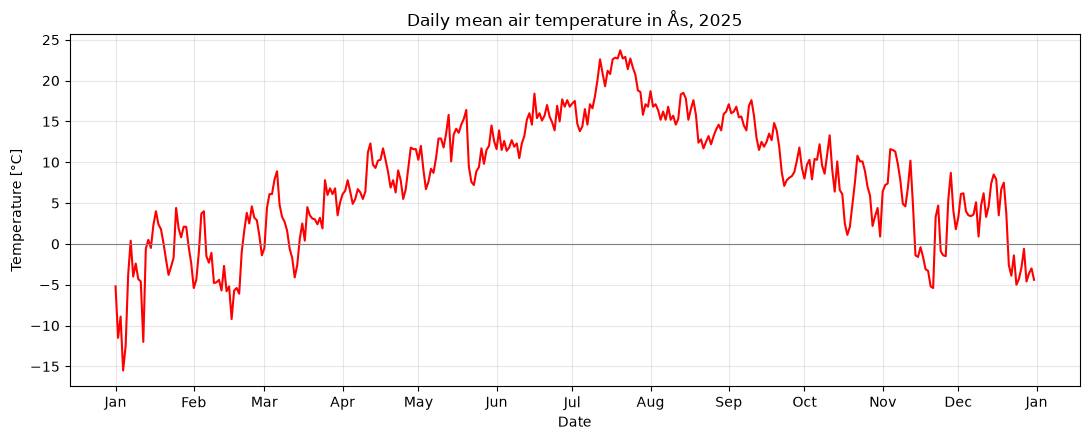

In [6]:
# Plot of the daily mean temperature in 2025
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(temp['referenceTime'], temp['value'], color='red')
ax.axhline(0, color='grey', linewidth=0.8)      # line at 0 °C

ax.set_title("Daily mean air temperature in Ås, 2025")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature [°C]")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
# Summary table for 2025

summary_2025 = temp['value'].agg(['mean', 'median', 'min', 'max']).round(1)
print("Daily mean air temperature in Ås, 2025 [°C]")
print(summary_2025.to_string())

Daily mean air temperature in Ås, 2025 [°C]
mean       7.9
median     8.3
min      -15.5
max       23.7


**Discussion:** *(Write 2–3 sentences here: e.g. when the coldest and warmest periods were,
what the mean and the min/max values are, and whether anything stands out.)*

## Task 2: Precipitation

Daily precipitation (sum over 24 hours) in Ås for 2025, shown together with the temperature from task 1.

In [8]:
# Downloading the data, for precipitation
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
'sources': 'SN17850', # sourceID for Ås
'elements': 'sum(precipitation_amount P1D)',
'referencetime': '2025-01-01/2026-01-01',   # end date is not included, so this keeps 31 December
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id,''))
# Extract JSON data
json = r.json()
data = json['data']

precipitation = pd.DataFrame()
rows = []


# Organising the data
for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    rows.append(row)


precipitation = pd.concat(rows, ignore_index=True)

precipitation = precipitation.reset_index()

# Convert the time value to something Python understands
precipitation['referenceTime'] = pd.to_datetime(precipitation['referenceTime'])

# Frost gives each day twice (timeOffset PT6H and PT18H), we keep PT6H = 06:00 to 06:00, the standard for precipitation
precipitation = precipitation[precipitation['timeOffset'] == 'PT6H'].reset_index(drop=True)

print("number of days:", len(precipitation))

number of days: 365


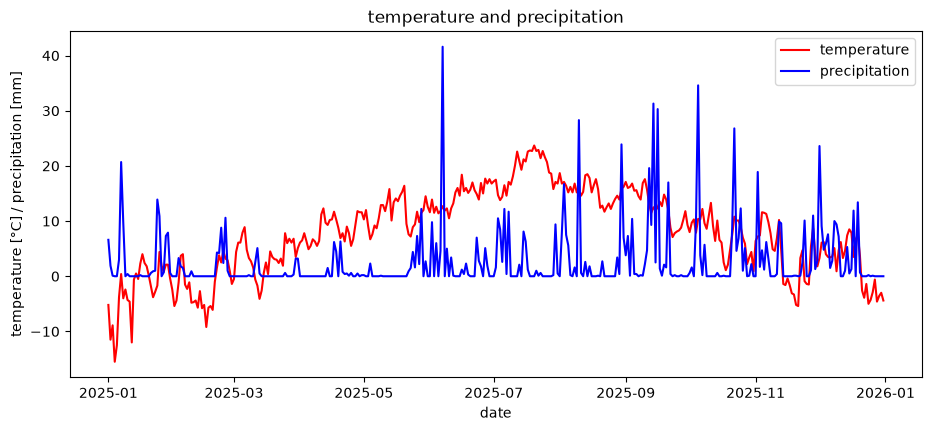

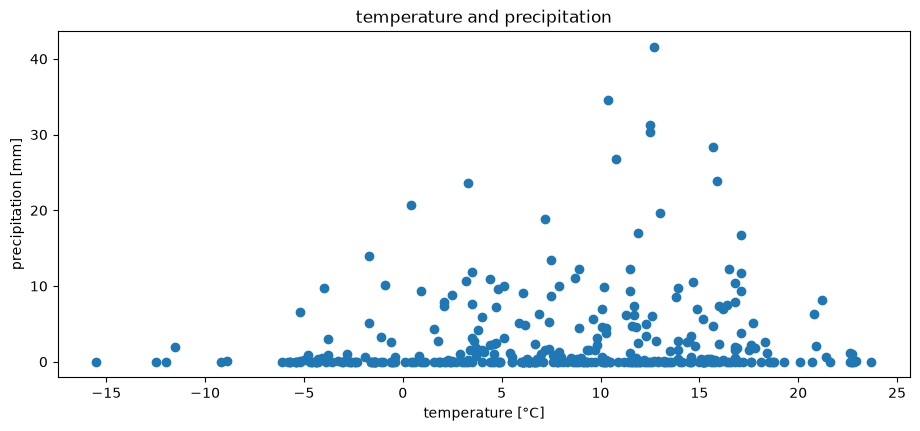

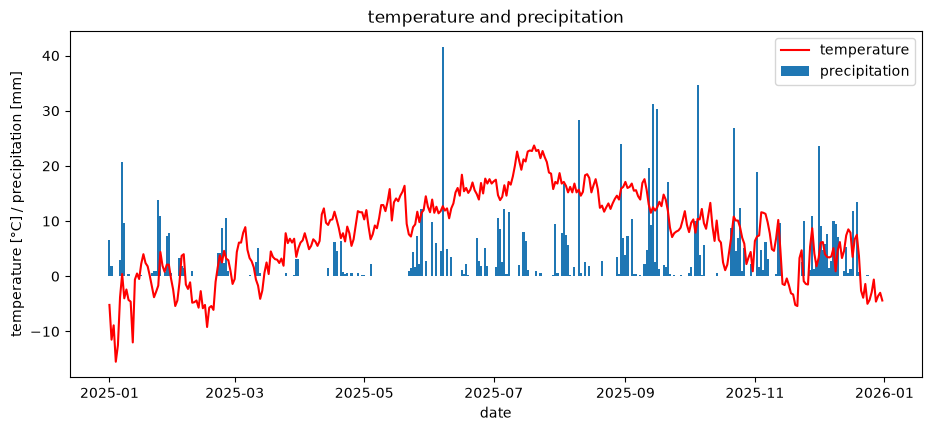

In [9]:
precipitation_value = precipitation["value"]
temp_value = temp["value"]

# Graph with both as lines
plt.figure(figsize=(11, 4.5))
plt.title("temperature and precipitation")
plt.plot(temp['referenceTime'], temp_value, label="temperature", color = "red")
plt.plot(precipitation['referenceTime'], precipitation_value, label="precipitation", color = "blue")
plt.xlabel("date")
plt.ylabel("temperature [°C] / precipitation [mm]")
plt.legend()
plt.show()

# Scatter plot to show relations between temperature and precipitation
plt.figure(figsize=(11, 4.5))
plt.title("temperature and precipitation")
plt.scatter(temp_value, precipitation_value)
plt.xlabel("temperature [°C]")
plt.ylabel("precipitation [mm]")
plt.show()

# Graph with precipitation as bar, 
plt.figure(figsize=(11, 4.5))
plt.title("temperature and precipitation")
plt.plot(temp['referenceTime'], temp_value, label="temperature", color = "red")
plt.bar(precipitation['referenceTime'], precipitation_value, width=1, label="precipitation")
plt.xlabel("date")
plt.ylabel("temperature [°C] / precipitation [mm]")
plt.legend()
plt.show()

**Discussion:** A pie chart does not make sense here, because it shows parts of a whole and not how
values change over time. For seeing how temperature and precipitation develop through the year, the
line + bar figure works best. The scatter plot answers a different question: whether warm days tend
to be wetter or drier. *(Comment on the correlation value: a value close to 0 means there is little
linear relationship.)*

## Task 3: Historical temperature data

The 2025 temperatures are compared with the same station 100 years earlier (1925).
To plot both years on one time axis, the 1925 dates are moved forward by 100 years, so that Jan 1st 1925 lines up with Jan 1st 2025.

In [10]:
# Downloading the data for temperature in 1925

endpoint = 'https://frost.met.no/observations/v0.jsonld'

# What we want to download
parameters = {
'sources': 'SN17850',                       # sourceID for Ås
'elements': 'mean(air_temperature P1D)',
'referencetime': '1925-01-01/1926-01-01',   # end date is not included, so this keeps 31 December
}

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth = (client_id,''))
# Extract JSON data
json = r.json()
data = json['data']

temp_1925 = pd.DataFrame()
rows = []


# Organising the data
for i in range(len(data)):
    row = pd.DataFrame(data[i]['observations'])
    row['referenceTime'] = data[i]['referenceTime']
    row['sourceId'] = data[i]['sourceId']
    rows.append(row)


temp_1925 = pd.concat(rows, ignore_index=True)

temp_1925 = temp_1925.reset_index()

# Convert the time value to something Python understands
temp_1925['referenceTime'] = pd.to_datetime(temp_1925['referenceTime'])

# For 1925 Frost gives only one version per day (timeOffset PT0H), the same as for 2025
print("number of days:", len(temp_1925))

number of days: 365


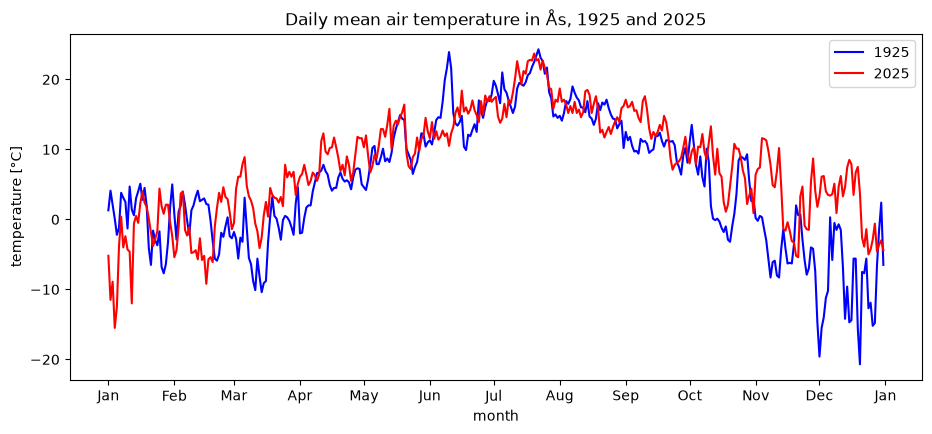

In [11]:
# Move the 1925 dates forward by 100 years, so that both years share the same x-axis
dates_1925_shifted = temp_1925['referenceTime'] + pd.DateOffset(years=100)

plt.figure(figsize = (11, 4.5))
plt.title("Daily mean air temperature in Ås, 1925 and 2025")
plt.plot(dates_1925_shifted, temp_1925['value'], label = "1925", color = "blue")
plt.plot(temp['referenceTime'], temp['value'], label = "2025", color = "red")
plt.xlabel("month")
plt.ylabel("temperature [°C]")
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b'))
plt.legend()
plt.show()

In [12]:
# Summary table for 1925 and 2025
summary_compare = pd.DataFrame({'1925': temp_1925['value'], '2025': temp['value']})
summary_compare = summary_compare.agg(['mean', 'median', 'min', 'max']).round(1)
summary_compare['difference'] = summary_compare['2025'] - summary_compare['1925']

print("Daily mean air temperature in Ås [°C], 1925 and 2025")
print(summary_compare.to_string())

Daily mean air temperature in Ås [°C], 1925 and 2025
        1925  2025  difference
mean     5.3   7.9         2.6
median   5.3   8.3         3.0
min    -20.7 -15.5         5.2
max     24.3  23.7        -0.6


**Discussion:**

The year 2025 was clearly warmer than 1925 - the mean temperature was 7.9 °C compared to 5.3 °C, a difference of 2.6 °C, and the median was 3.0 °C higher. The plot shows that the difference is not spread evenly over the year. The summers were very similar, most of the difference comes from the winter months: November and December 1925 were much colder.

## Task 4: Heatwaves

In Norway, a heatwave is at least 5 days in a row where the maximum temperature is 27 °C or more.

In [13]:
def get_station_name(station_id, client_id):

    # Ask frost.met.no for information about the station
    endpoint = 'https://frost.met.no/sources/v0.jsonld'
    parameters = {'ids': station_id}
    r = requests.get(endpoint, parameters, auth=(client_id,''))
    json = r.json()
    data = json['data']

    # Frost writes names in capital letters ('ÅS'), .title() turns it into 'Ås'
    return data[0]['name'].title()


def find_heatwaves(max_temp, threshold = 27, min_days = 5):

    # Dates of all days that are hot enough, in order
    hot_days = max_temp.loc[max_temp['value'] >= threshold, 'referenceTime'].sort_values().tolist()

    # List where we save the heatwaves we find
    heatwaves = []
    if len(hot_days) == 0:
        return heatwaves

    start = previous = hot_days[0]
    for day in hot_days[1:]:
        if day - previous == pd.Timedelta(days=1):

            # The day after the previous hot day: the hot period continues
            previous = day
        else:

            # A gap: the hot period has ended, save it if it was long enough
            if (previous - start).days + 1 >= min_days:
                heatwaves.append((start, previous))
            start = previous = day

    # Check the last hot period too
    if (previous - start).days + 1 >= min_days:
        heatwaves.append((start, previous))

    return heatwaves


def count_heatwaves(station_id, year, client_id):
    
    # Downloading the max temperature for the chosen station and year
    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
    'sources': station_id,
    'elements': 'max(air_temperature P1D)',
    'referencetime': f'{year}-01-01/{year + 1}-01-01',   # end date is not included
    }

    # Issue an HTTP GET request
    r = requests.get(endpoint, parameters, auth = (client_id,''))
    # Extract JSON data
    json = r.json()
    data = json['data']

    max_temp = pd.DataFrame()
    rows = []

    # Organising the data
    for i in range(len(data)):
        row = pd.DataFrame(data[i]['observations'])
        row['referenceTime'] = data[i]['referenceTime']
        row['sourceId'] = data[i]['sourceId']
        rows.append(row)

    max_temp = pd.concat(rows, ignore_index = True)

    # Convert the time value to something Python understands
    max_temp['referenceTime'] = pd.to_datetime(max_temp['referenceTime'])

    # Frost can give each day more than once (different timeOffset), keep only one version
    # We use PT0H (midnight to midnight) like in task 1, if the station has it

    if 'PT0H' in max_temp['timeOffset'].values:
        offset = 'PT0H'
    else:
        offset = max_temp['timeOffset'].iloc[0]
    max_temp = max_temp[max_temp['timeOffset'] == offset].reset_index(drop=True)


    # Find the heatwaves
    heatwaves = find_heatwaves(max_temp)

    # Write the summary to a yml file
    summary = {
        'dates': [f"{start:%Y-%m-%d} - {end:%Y-%m-%d}" for start, end in heatwaves],
        'station_id': station_id,
        'station_name': get_station_name(station_id, client_id),
        'year': year,
    }
    filename = f'heatwave_summary_{station_id}_{year}.yml'
    with open(filename, 'w') as f:
        yaml.safe_dump(summary, f)

    return len(heatwaves)

In [14]:
n = count_heatwaves('SN17850', 2025, client_id)
print("Number of heatwaves in Ås in 2025:", n)
print()

with open('heatwave_summary_SN17850_2025.yml') as f:
    print(f.read())

Number of heatwaves in Ås in 2025: 1

dates:
- 2025-07-16 - 2025-07-20
station_id: SN17850
station_name: "\xC5s"
year: 2025



In [15]:
# Another station and year (shows that the code works generally)

# Oslo - Blindern in 2018, a known hot summer
n = count_heatwaves('SN18700', 2018, client_id)
print("Number of heatwaves in Oslo - Blindern in 2018:", n)
print()

with open('heatwave_summary_SN18700_2018.yml') as f:
    print(f.read())

Number of heatwaves in Oslo - Blindern in 2018: 2

dates:
- 2018-05-29 - 2018-06-03
- 2018-07-19 - 2018-07-28
station_id: SN18700
station_name: Oslo - Blindern
year: 2018



   **Discussion:** 

We found one heatwave in Ås in 2025, from 16 to 20 July. Frost gives the daily maximum temperature in two versions: midnight to midnight (PT0H, which we
use, as in task 1) and 18:00 to 18:00 (PT18H). With PT18H the same heatwave lasts until 22 July, so the choice of version can change the length of a heatwave. To show that the function works for any station and year, we also ran it for Oslo - Blindern in 2018, which gave two heatwaves
(29 May to 3 June and 19 to 28 July).

## Task 5: Moving average temperature

A 7-day moving average smooths out the day-to-day changes, so longer trends are easier to see.
For each day, the function takes the average of that day and the 6 days before it. The first 6 days have no value, because there are not yet 7 days to average over.

In [16]:
def moving_average(values, window=7):
    result = []
    for i in range(len(values)):
        if i < window - 1:
            # Not enough days yet for a full window
            result.append(float('nan'))
        else:
            # Average of this day and the (window - 1) days before it
            result.append(values.iloc[i - window + 1 : i + 1].sum() / window)
    return pd.Series(result)

In [17]:
# Use the moving average function on the 2025 daily mean temperature from task 1
temp['moving_average'] = moving_average(temp['value'])

# Show the first 10 days to check the result:
print(temp[['referenceTime', 'value', 'moving_average']].head(10))

# the first 6 days (1-6 January) are NaN because there are not 7 days yet
# the first value is on 7 January: the average of 1-7 January
# the numbers on the left are row numbers, Python starts counting at 0


              referenceTime  value  moving_average
0 2025-01-01 00:00:00+00:00   -5.2             NaN
1 2025-01-02 00:00:00+00:00  -11.5             NaN
2 2025-01-03 00:00:00+00:00   -8.9             NaN
3 2025-01-04 00:00:00+00:00  -15.5             NaN
4 2025-01-05 00:00:00+00:00  -12.5             NaN
5 2025-01-06 00:00:00+00:00   -3.8             NaN
6 2025-01-07 00:00:00+00:00    0.4       -8.142857
7 2025-01-08 00:00:00+00:00   -4.0       -7.971429
8 2025-01-09 00:00:00+00:00   -2.4       -6.671429
9 2025-01-10 00:00:00+00:00   -4.3       -6.014286


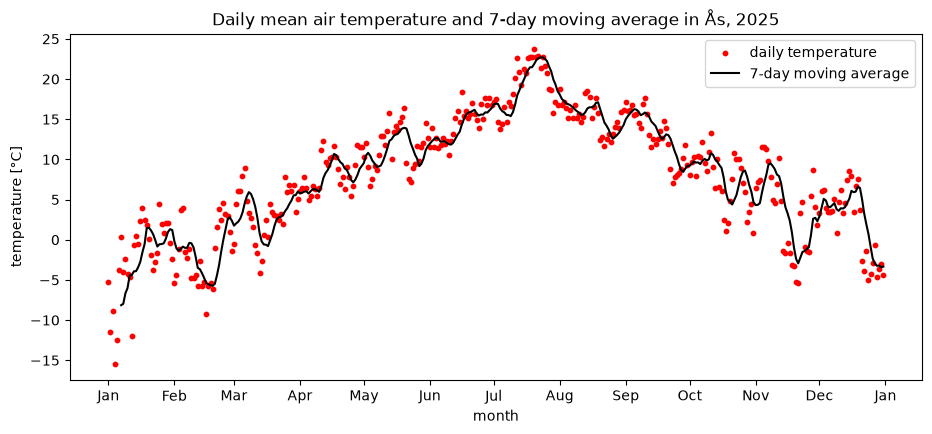

In [18]:
plt.figure(figsize=(11, 4.5))
plt.title("Daily mean air temperature and 7-day moving average in Ås, 2025")
plt.scatter(temp['referenceTime'], temp['value'], s=10, label="daily temperature", color = "red")
plt.plot(temp['referenceTime'], temp['moving_average'], label="7-day moving average", color = "black")
plt.xlabel("month")
plt.ylabel("temperature [°C]")
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b'))
plt.legend()
plt.show()

**Discussion:** 

The 7-day moving average removes most of the day-to-day variation and shows the seasonal pattern more clearly. The daily values vary much more in winter than in summer. Because each value is the average of that day and the 6 days before it, the line starts on 7 January and reacts a few days late to sudden changes, such as the drop in early August.